In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

----

# Simple Linear Regression using Numpy `np.polyfit`
Simple linear regression uses **only one** independent variable(Feature) to explain/predict the dependent variable (label)

In [2]:
df = pd.read_csv(r"C:\Users\Olade\Documents\Python Notebooks\UNZIP_FOR_NOTEBOOKS_FINAL\08-Linear-Regression-Models\Advertising.csv")

In [3]:
df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [4]:
df['total_ads_spend'] = df['TV'] + df['radio'] + df['newspaper']

In [5]:
df.head()

,TV,radio,newspaper,sales,total_ads_spend
0,230.1,37.8,69.2,22.1,337.1
1,44.5,39.3,45.1,10.4,128.9
2,17.2,45.9,69.3,9.3,132.4
3,151.5,41.3,58.5,18.5,251.3
4,180.8,10.8,58.4,12.9,250.0


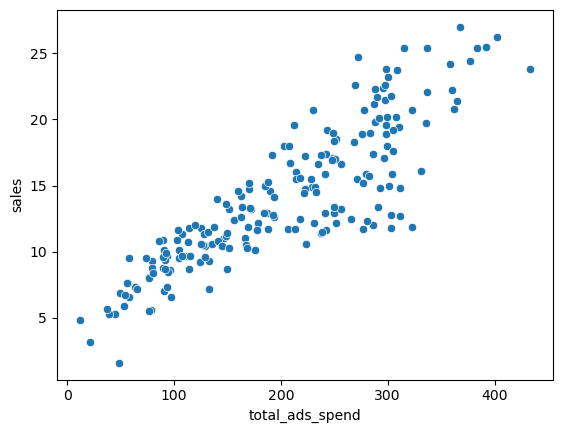

In [6]:
sns.scatterplot(data=df, x='total_ads_spend', y='sales');

In [7]:
# sns.regplot(data=df, x='total_ads_spend', y='sales');

In [8]:
X = df['total_ads_spend']
y = df['sales']

In [9]:
slope, intercept = np.polyfit(X,y,deg=1)

In [10]:
potential_ads_spend = np.linspace(0,500,100) # The range of the total_ads_spend in the df

In [11]:
predicted_sales = slope*potential_ads_spend + intercept

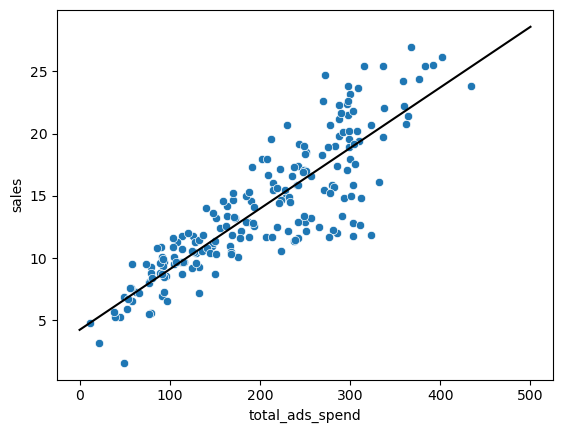

In [12]:
sns.scatterplot(data=df, x='total_ads_spend', y='sales')
sns.lineplot(x=potential_ads_spend, y=predicted_sales, color='black');

**Given a total ads spend of 200, what is the value of the predicted sales?**

In [13]:
spend = 200
predicted_sales = slope*spend + intercept

In [14]:
predicted_sales

np.float64(13.98060407984596)

### Polynomial regression using `np.polyfit`

In [15]:
b3,b2,b1,b0 = np.polyfit(X,y,deg=3)

In [16]:
pred_sales = b3*potential_ads_spend**3 + b2*potential_ads_spend**2 + b1*potential_ads_spend + b0

<Axes: xlabel='total_ads_spend', ylabel='sales'>

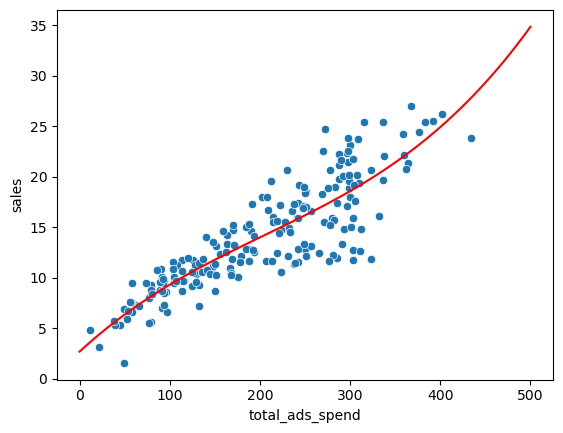

In [17]:
sns.lineplot(x=potential_ads_spend, y=pred_sales, color='red')
sns.scatterplot(data=df, x='total_ads_spend', y='sales')

**Remarks on `np.polyfit`**
- Linear/Polynomial regression of one independent variable
- No built-in method to evaluate the performance of fitted lines. (Is the curved fit better than the linear fit?)
- No information of statistical coefficients such as **P-values**, **R-squared**, **Standard errors** etc
----

----
# Linear Regression using Scikit-learn
With Scikit-learn, it is possible to evaluate the relationship between **multiple** independent variables (Features) and the dependent variable (label)

- from `sklearn.model_selection` import `train_test_split`
- from `sklearn.linear_model` import `LinearRegression`
- from `sklearn.metrics` import `mean_absolute_error`, `mean_squared_error`

In [18]:
df = pd.read_csv(r"C:\Users\Olade\Documents\Python Notebooks\UNZIP_FOR_NOTEBOOKS_FINAL\08-Linear-Regression-Models\Advertising.csv")
df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


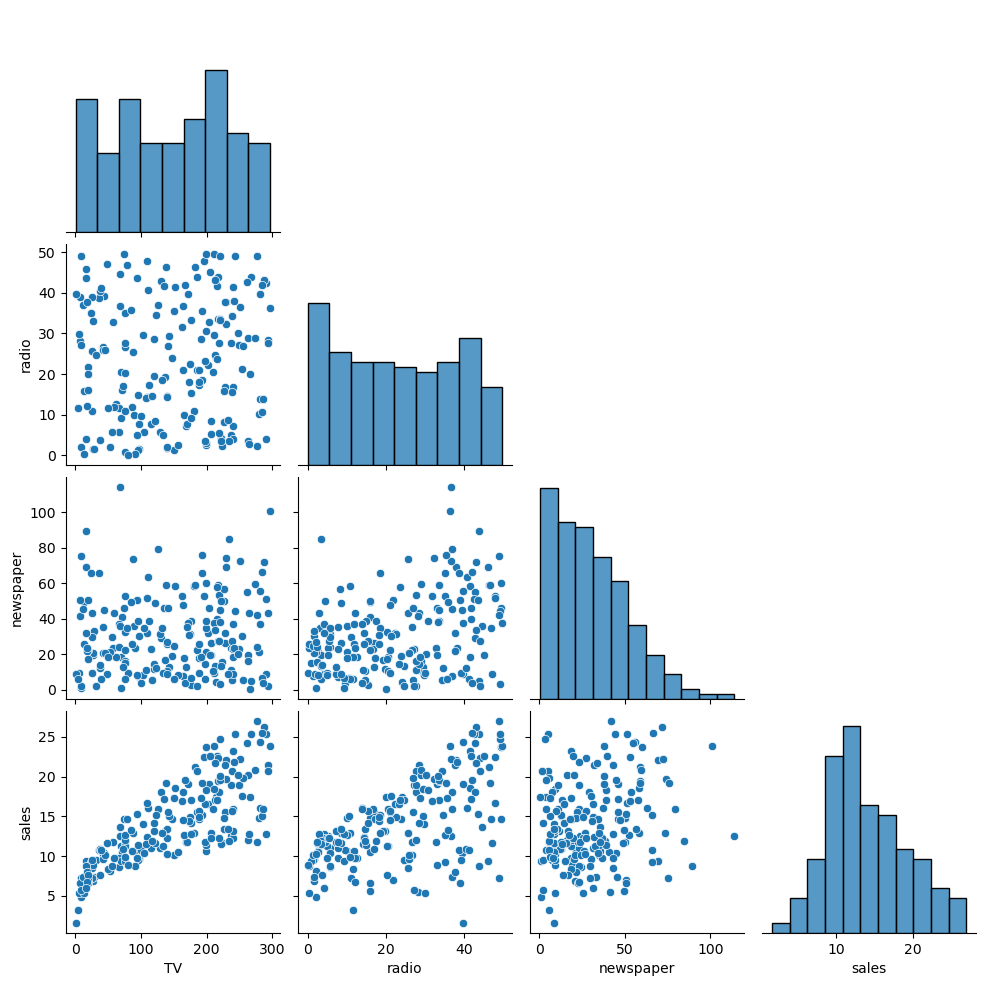

In [19]:
sns.pairplot(data=df, corner=True)

In [20]:
# Separate the data into features and label
X = df.drop('sales', axis=1) 
X

,TV,radio,newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4
...,...,...,...
195,38.2,3.7,13.8
196,94.2,4.9,8.1
197,177.0,9.3,6.4
198,283.6,42.0,66.2


In [21]:
y = df['sales']
y

0      22.1
1      10.4
2       9.3
3      18.5
4      12.9
       ... 
195     7.6
196     9.7
197    12.8
198    25.5
199    13.4
Name: sales, Length: 200, dtype: float64

In [22]:
from sklearn.model_selection import train_test_split

In [23]:
# help(train_test_split)

In [24]:
 X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

In [25]:
X_train.head()

,TV,radio,newspaper
85,193.2,18.4,65.7
183,287.6,43.0,71.8
127,80.2,0.0,9.2
53,182.6,46.2,58.7
100,222.4,4.3,49.8


In [26]:
y_train.head()

85     15.2
183    26.2
127     8.8
53     21.2
100    11.7
Name: sales, dtype: float64

In [27]:
from sklearn.linear_model import LinearRegression

In [28]:
# help(LinearRegression)

In [29]:
model = LinearRegression()

In [30]:
model.fit(X_train, y_train)

LinearRegression()

In [31]:
y_test_predictions = model.predict(X_test)

### Performance evaluation of Scikit-learn predictions

In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [33]:
df['sales'].mean()

np.float64(14.0225)

In [34]:
y_test.std()

5.358234330564774

<Axes: xlabel='sales', ylabel='Count'>

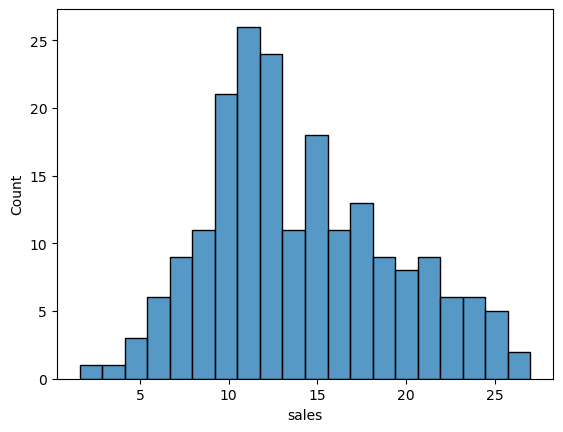

In [35]:
sns.histplot(data=df, x='sales', bins=20)

In [36]:
mean_absolute_error(y_test, y_test_predictions)

1.2137457736144803

In [37]:
# RMSE - Root Mean Squared Error
np.sqrt(mean_squared_error(y_test, y_test_predictions))

np.float64(1.516151937599388)

When RMSE is considerably larger than MAE, it suggests that the model has some relatively large errors compared with its typical error.

- MAE tells you the average magnitude of prediction errors.
- RMSE tells you more about the impact of large prediction errors.
- The ratio RMSE/MAE can help assess how pronounced those large errors are.

### Residual Analysis
**Residuals plotted against the predicted values** for a well-fitted model will show either of the following patterns:
- **Ideal pattern**: Random cloud of points centred around 0 with roughly constant vertical spread(homoscedasticity)
- **Curved or wave pattern**: suggests missing non-linear terms or an incorrect functional form (non-linearity). **U-shape indicates missing squared term(s)**. **S-shape indicates higher-order terms or a transformation such as log**. For multiple independent variables, the plot of each variable against the residual will help to find which one is responsible for the curved/wave pattern. 

In [38]:
y_fitted = model.predict(X_train)

**P.S. Calculate the error metrics on the fitted data to check the model performance on the training data.**

In [39]:
residuals = y_train - y_fitted

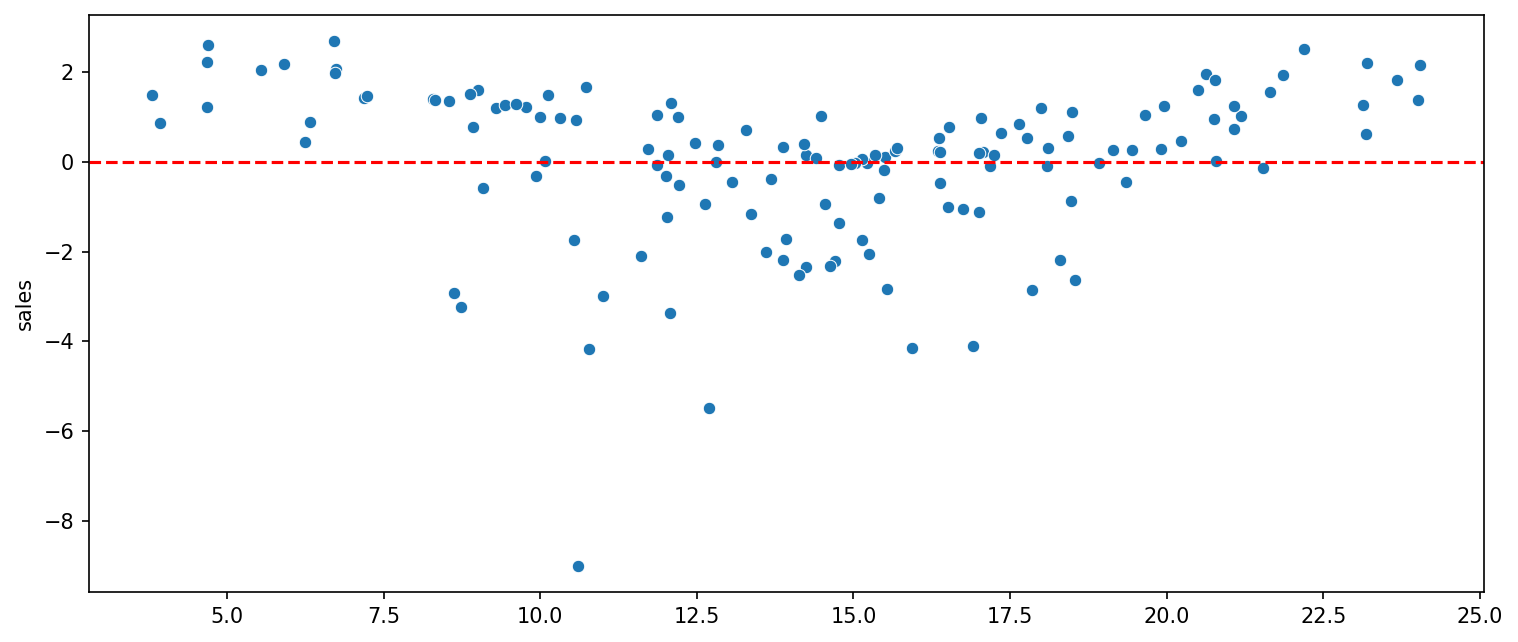

In [40]:
# The plot of the residuals against the fitted y value for the training set
plt.figure(figsize=(12,5), dpi=150)
sns.scatterplot(x=y_fitted, y=residuals)
plt.axhline(y=0, color='red',ls='--');

**This is the classic U-shaped pattern from fitting a straight-line model to curved data**

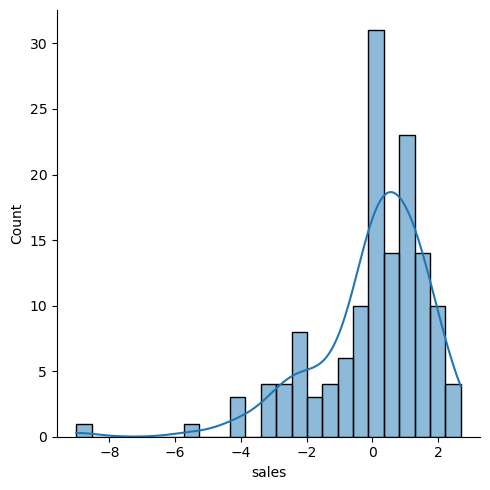

In [41]:
sns.displot(residuals, bins=25, kde=True);

In [42]:
test_residuals = y_test - y_test_predictions

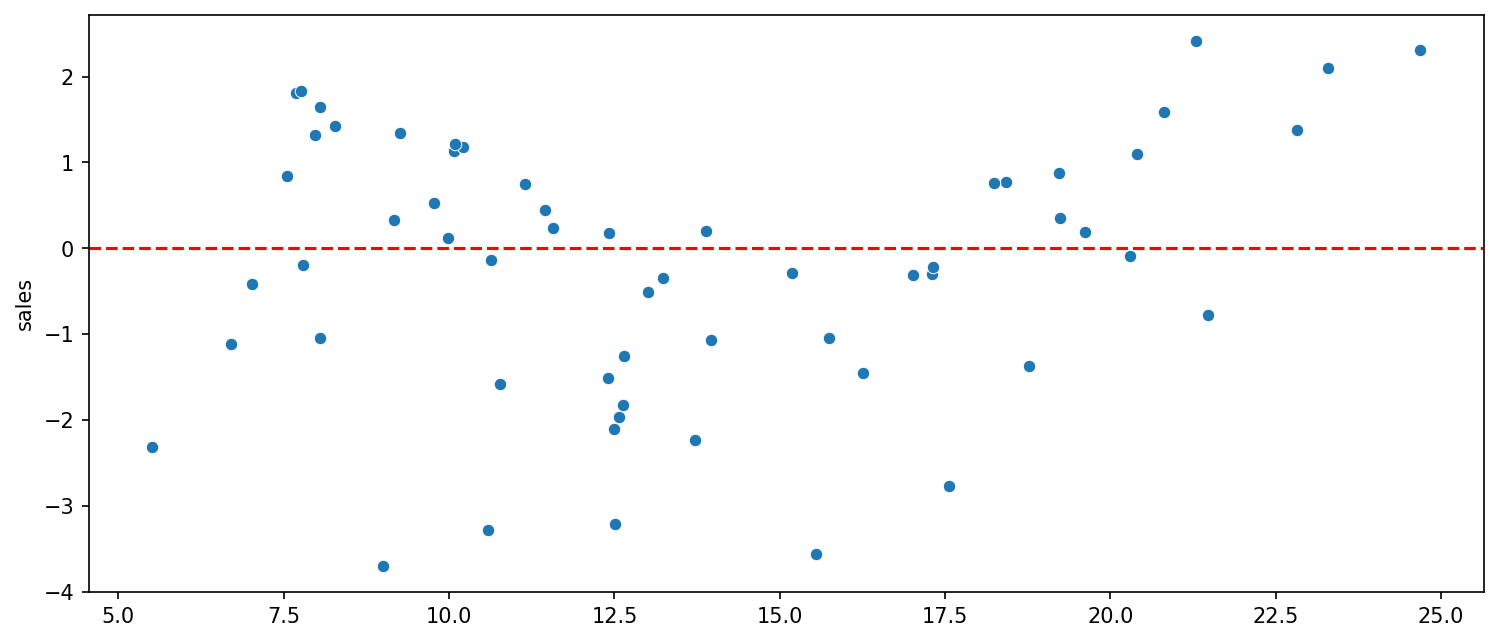

In [43]:
# The plot of the residuals against the fitted y-value(predictions) of the test set
plt.figure(figsize=(12,5), dpi=150)
sns.scatterplot(x=y_test_predictions, y=test_residuals)
plt.axhline(y=0, color='red',ls='--');

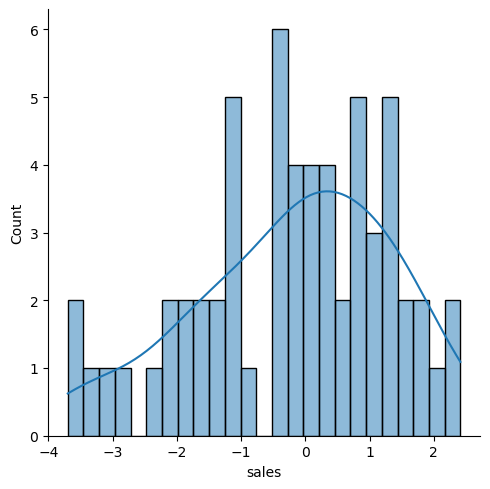

In [44]:
sns.displot(test_residuals,bins=25, kde=True);

### Model Coefficients and Model Deployment

In [45]:
final_model = LinearRegression()

In [47]:
final_model.fit(X,y)

LinearRegression()

In [48]:
final_model.coef_

array([ 0.04576465,  0.18853002, -0.00103749])

Each coefficient represents the marginal effect of the independent variable (feature) on the dependent variable (label) while the other features are constant. 

0.04576465 is the marginal effect of TV ads on sales while radio and newspaper ads are constant

In [49]:
X.head(2)

,TV,radio,newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1


In [50]:
from joblib import dump, load

In [51]:
dump(final_model, 'final_sales_model.joblib')

['final_sales_model.joblib']

In [52]:
loaded_model = load('final_sales_model.joblib')

In [53]:
loaded_model.coef_

array([ 0.04576465,  0.18853002, -0.00103749])

In [65]:
campaign = [[149, 22,12], [149, 220,12]]

In [66]:
loaded_model.predict(campaign)

C:\Users\Olade\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([13.893032  , 51.22197535])

----
# Polynomial Regression Using Scikit-learn `PolynomialFeatures`

- from `sklearn.preprocessing` import `PolynomialFeatures`
- Polynomial features allow a linear regression model to capture a curved relationship between variables rather than just a straight-line relationship.
- Polynomial transformation creates additional features (squared, cubed, interaction features etc.) that allow linear regression to model nonlinear relationships.
- **Interaction features** are additional variables created by multiplying two independent variables together. They allow a linear regression model to capture situations where the effect of one variable on the dependent variable depends on the value of another variable.
- **The regression coefficient of an interaction variable explains how the effect of one independent variable on the dependent variable changes when the other independent variable increases by one unit.**

In [68]:
df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [71]:
# Features
X.head()

,TV,radio,newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4


In [74]:
# Label
y.head()

0    22.1
1    10.4
2     9.3
3    18.5
4    12.9
Name: sales, dtype: float64

In [75]:
from sklearn.preprocessing import PolynomialFeatures

In [76]:
polynomial_converter = PolynomialFeatures(degree=2, include_bias=False)

In [77]:
polynomial_converter.fit(X)

PolynomialFeatures(include_bias=False)

In [81]:
poly_features = polynomial_converter.transform(X)

The fit-then-transform process above can be achieved using the 
`polynomial_converter.fit_transform()` function

In [82]:
poly_features.shape

(200, 9)

In [96]:
features_name = polynomial_converter.get_feature_names_out(X.columns)
features_name

array(['TV', 'radio', 'newspaper', 'TV^2', 'TV radio', 'TV newspaper',
       'radio^2', 'radio newspaper', 'newspaper^2'], dtype=object)

In [86]:
# This contains the original X values, the interaction terms and square terms. 
poly_features

array([[ 230.1 ,   37.8 ,   69.2 , ..., 1428.84, 2615.76, 4788.64],
       [  44.5 ,   39.3 ,   45.1 , ..., 1544.49, 1772.43, 2034.01],
       [  17.2 ,   45.9 ,   69.3 , ..., 2106.81, 3180.87, 4802.49],
       ...,
       [ 177.  ,    9.3 ,    6.4 , ...,   86.49,   59.52,   40.96],
       [ 283.6 ,   42.  ,   66.2 , ..., 1764.  , 2780.4 , 4382.44],
       [ 232.1 ,    8.6 ,    8.7 , ...,   73.96,   74.82,   75.69]])

In [95]:
poly_features = pd.DataFrame(data=poly_features, columns=features_name)
poly_features.head()

,TV,radio,newspaper,TV^2,TV radio,TV newspaper,radio^2,radio newspaper,newspaper^2
0,230.1,37.8,69.2,52946.01,8697.78,15922.92,1428.84,2615.76,4788.64
1,44.5,39.3,45.1,1980.25,1748.85,2006.95,1544.49,1772.43,2034.01
2,17.2,45.9,69.3,295.84,789.48,1191.96,2106.81,3180.87,4802.49
3,151.5,41.3,58.5,22952.25,6256.95,8862.75,1705.69,2416.05,3422.25
4,180.8,10.8,58.4,32688.64,1952.64,10558.72,116.64,630.72,3410.56


In [91]:
X_train, X_test, y_train, y_test = train_test_split(poly_features, y, test_size=0.3, random_state=101)

In [92]:
model = LinearRegression()

In [93]:
model.fit(X_train, y_train)

LinearRegression()

In [97]:
model.coef_

array([ 5.17095811e-02,  1.30848864e-02,  1.20000085e-02, -1.10892474e-04,
        1.14212673e-03, -5.24100082e-05,  3.34919737e-05,  1.46380310e-04,
       -3.04715806e-05])

In [106]:
coefficients = pd.DataFrame({
    'Feature': features_name,
    'Coefficient': model.coef_
})
coefficients

,Feature,Coefficient
0,TV,0.051710
1,radio,0.013085
2,newspaper,0.012000
3,TV^2,-0.000111
4,TV radio,0.001142
5,TV newspaper,-0.000052
6,radio^2,0.000033
7,radio newspaper,0.000146
8,newspaper^2,-0.000030


**Performance Evaluation**

In [107]:
test_predictions = model.predict(X_test)

In [110]:
MAE = mean_absolute_error(y_test, test_predictions)
MAE

0.48967980448037096

In [112]:
MSE = mean_squared_error(y_test, test_predictions)
MSE

0.44175055104035904

In [114]:
RMSE = np.sqrt(mean_squared_error(y_test, test_predictions))
RMSE

np.float64(0.6646431757269152)

**Residual Analysis**

In [116]:
y_fitted = model.predict(X_train)

In [126]:
residuals = y_train - y_fitted
residuals

85    -0.257448
183    0.551874
127    0.171448
53    -0.416009
100   -0.562862
         ...   
63     0.755020
70    -0.303469
81     0.014424
11     0.049070
95    -0.394671
Name: sales, Length: 140, dtype: float64

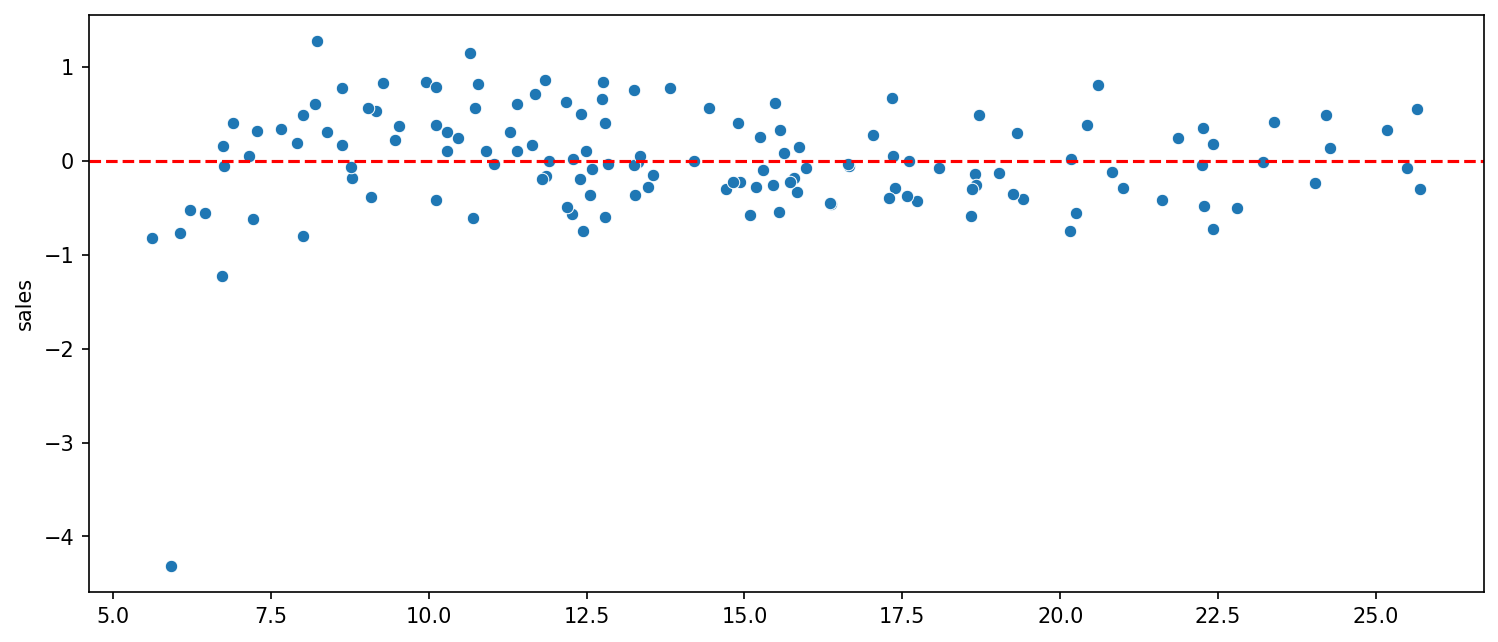

In [130]:
plt.figure(figsize=(12,5), dpi=150)
sns.scatterplot(x=y_fitted, y=residuals)
plt.axhline(y=0, color='red', ls='--');

**Note on Scikit-learn Linear Regression**: 
- Scikit-learn's LinearRegression is particularly **useful when the primary objective is prediction.**
- However, it does **not provide** a built-in **statistical summary of the regression results**, making it less convenient to assess the statistical significance of individual regressors (e.g., p-values, standard errors and confidence intervals).
- When the primary objective is **statistical inference** and understanding the relationships between variables, **Statsmodels** is a more suitable choice for regression analysis.

----
## Bias-Variance Trade-off
### Overfitting and Underfitting

----

**Overfitting**
- The model fits too much noise from the data 
- This often results in low error on training sets but high error on test/validation sets
- High variance and low bias model resulting in poor generalisation of unseen data

**Underfitting**
- The model does not capture the undelying trenc of the data and does not fit the data well enough
- High bias and low variance model that is often the result of an excessively simple model

**How to identify/choose the optimal level of complexity for generalisation**
- As model complexity increases, the training error generally decreases because the model becomes more flexible in capturing patterns in the training data.
- The test error typically decreases initially as the model captures more of the underlying patterns. However, beyond an optimal level of complexity, the test error may increase due to overfitting.
- To visualise this behaviour, we can build models with varying levels of complexity, calculate and store their training and test error metrics, and plot the results(errors) against model complexity(e.g., polynomial degree)

In [132]:
train_rmse_errors = []
test_rmse_errors = []

for d in range(1,10):
    poly_converter = PolynomialFeatures(degree=d, include_bias=False)
    poly_features = poly_converter.fit_transform(X)

    X_train, X_test, y_train, y_test = train_test_split(poly_features, y, test_size=0.3, random_state=101)

    model = LinearRegression()
    model.fit(X_train,y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

    train_rmse_errors.append(train_rmse)
    test_rmse_errors.append(test_rmse)

In [133]:
train_rmse_errors

[np.float64(1.734594124329376),
 np.float64(0.5879574085292232),
 np.float64(0.4339344356902066),
 np.float64(0.35170836883993495),
 np.float64(0.2509342951990972),
 np.float64(0.20953728857167148),
 np.float64(0.2204686586946699),
 np.float64(0.27149790330285106),
 np.float64(0.513204282355187)]

In [134]:
test_rmse_errors

[np.float64(1.5161519375993877),
 np.float64(0.6646431757269152),
 np.float64(0.5803286825156331),
 np.float64(0.5077742623872589),
 np.float64(2.5758247707699113),
 np.float64(9.871388816488105),
 np.float64(41.33198333125283),
 np.float64(3103.172520177059),
 np.float64(12768.365758643058)]

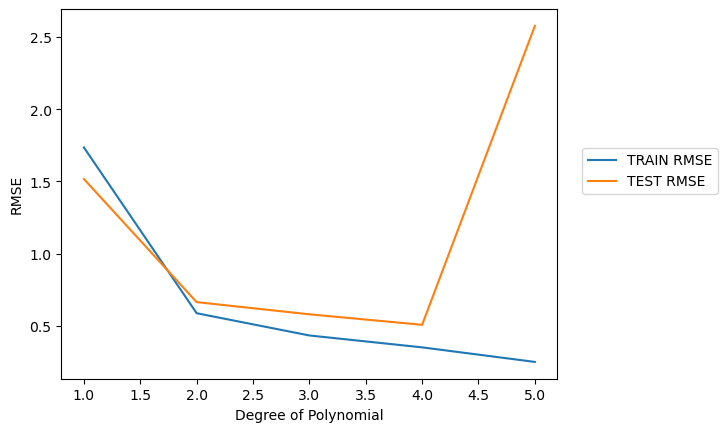

In [139]:
plt.plot(range(1,6), train_rmse_errors[:5], label='TRAIN RMSE')
plt.plot(range(1,6), test_rmse_errors[:5], label='TEST RMSE')

plt.ylabel('RMSE')
plt.xlabel('Degree of Polynomial')
plt.legend(loc=(1.05,0.5));